# 413 – VQC on the *ad hoc* Dataset, with a Train / Test Split

In `410`–`412` the data was a simple diagonal split that any classical model could learn.
Here we use the **ad hoc dataset** from *Havlíček et al., "Supervised learning with
quantum-enhanced feature spaces", Nature 567, 209 (2019)*
([arXiv:1804.11326](https://arxiv.org/abs/1804.11326)).  It is generated *with* the
`ZZFeatureMap`, so its class boundaries have exactly the shape that this quantum feature map
can express – and that are awkward for common classical kernels.

This time we also do things properly: the model is trained on a **training set** and judged on
**unseen test data**.

**You will learn to**
* load the ad hoc dataset (`402` introduced it);
* configure a `VQC` with a feature map, an ansatz and the noise-robust **SPSA** optimiser;
* evaluate on held-out data and on fresh samples.

**Prerequisites:** `402`, `412`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

from qiskit.circuit.library import n_local, zz_feature_map
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.datasets import ad_hoc_data
from qiskit_machine_learning.optimizers import SPSA
from qiskit_machine_learning.utils import algorithm_globals

seed = 10599
algorithm_globals.random_seed = seed

## The data

`ad_hoc_data` returns 20 training points per class and – here – 30 further points per class.
We split those 60 points into three groups of 10 per class: a **test set** for the score, and
two extra sets (`datapoints`, `more_datapoints`) to practise `predict` on.

The background picture drawn by `plot_data=True` shows the regions of the two classes – note
how they interleave.  The `gap` parameter leaves a margin between them.

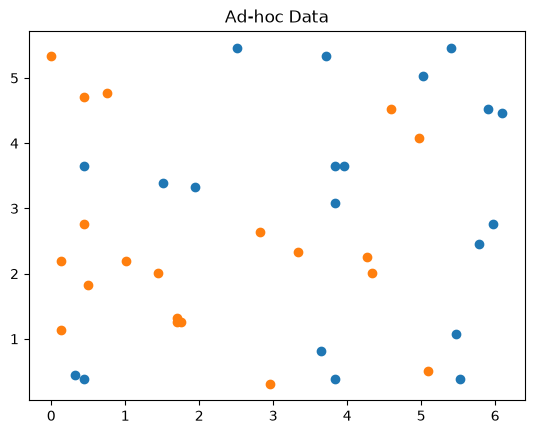

{'A': 0, 'B': 1}


In [3]:
from qiskit_machine_learning.datasets import ad_hoc_data
feature_dim = 2
# ad_hoc_data now returns feature/label arrays (class 0 = 'A', class 1 = 'B') instead of
# {class: samples} dictionaries. We draw 30 test points per class from the same distribution:
# 10 for testing, 10 as `datapoints` to predict and 10 as `more_datapoints`.
train_features, train_labels, test_all, test_all_labels = ad_hoc_data(
    training_size=20, test_size=30, n=feature_dim, gap=0.3, plot_data=True, one_hot=False)

def _split(start, stop):
    idx = np.r_[start:stop, 30 + start:30 + stop]     # rows of class A, then class B
    return test_all[idx], test_all_labels[idx]

test_features, test_labels = _split(0, 10)
datapoints = _split(10, 20)
more_datapoints = _split(20, 30)
class_labels = ['A', 'B']
class_to_label = {name: i for i, name in enumerate(class_labels)}
print(class_to_label)

## Setting up the VQC

* **Feature map** – `zz_feature_map` with 2 repetitions: the same circuit that generated the data.
* **Ansatz** – `n_local` with $R_Y$ and $R_Z$ rotations and $CZ$ entanglers, 3 repetitions.
* **Optimiser** – **SPSA** (*Simultaneous Perturbation Stochastic Approximation*).  It estimates
  the gradient from just two circuit evaluations, whatever the number of parameters, and copes
  well with the shot noise of a sampler – the standard choice on real hardware.

Training takes about a minute.

In [4]:
feature_dim = 2
feature_map = zz_feature_map(feature_dimension=feature_dim, reps=2)
var_form = n_local(feature_dim, ['ry', 'rz'], 'cz', reps=3)
objective_func_vals = []
def callback_graph(num_evals, weights, obj_func_eval, step_size, accepted):
    """SPSA reports: evaluations so far, weights, loss, step size, step accepted?"""
    clear_output(wait=True)
    objective_func_vals.append(obj_func_eval)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()

# SPSA has its own callback (with 5 arguments), so we attach the live plot to the optimiser
optimizer = SPSA(maxiter=40, callback=callback_graph)

vqc = VQC(feature_map=feature_map, ansatz=var_form, optimizer=optimizer,
          sampler=StatevectorSampler(default_shots=1024, seed=seed))
vqc.fit(train_features, train_labels)

## Evaluation on unseen data

`score` gives the accuracy on the test set; `predict` labels new points.

In [5]:
def report(name, model, points):
    predicted = model.predict(points[0])
    print(f'{name}:')
    print(f'  ground truth: {[class_labels[i] for i in points[1]]}')
    print(f'  prediction:   {[class_labels[i] for i in predicted]}')
    print(f'  success rate: {100 * np.mean(predicted == points[1]):.0f}%')
print(f'Training accuracy: {vqc.score(train_features, train_labels):.2f}')
print(f'Testing accuracy:  {vqc.score(test_features, test_labels):.2f}')
print()
report('Prediction from datapoints set', vqc, datapoints)

Training accuracy: 0.97


Testing accuracy:  1.00



Prediction from datapoints set:
  ground truth: ['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B']
  prediction:   ['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B']
  success rate: 100%


VQC follows the scikit-learn interface, so the trained model can label any further points
directly.

In [6]:
report('Prediction from more_datapoints set', vqc, more_datapoints)
# Note: trained qiskit-machine-learning models can be saved with vqc.save(path) and
# restored with VQC.load(path).

Prediction from more_datapoints set:
  ground truth: ['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B']
  prediction:   ['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B']
  success rate: 100%


## Key takeaways
* Always judge a model on data it has **not** been trained on.
* A VQC is only as good as its **feature map**: the ad hoc data is easy for the matching ZZ
  feature map and hard for most others.
* SPSA is the go-to optimiser when evaluations are noisy (shots, hardware).
* Compare with `410`–`412`: on data that *matches* the feature map, the same kind of model
  reaches (near-)perfect accuracy.

## Try it yourself
1. Increase `SPSA(maxiter=...)` to 100.  Do training and test accuracy improve?
2. Replace the feature map by `zz_feature_map(feature_dim, reps=1)`.  What happens to the test
   accuracy?  Why?
3. Make the task easier or harder with `gap=0.6` or `gap=0.1` in `ad_hoc_data`.

**Next:** `415-QSVM-Binary` – the same dataset, solved with a **quantum kernel** instead of a
trained circuit.